In [31]:
import numpy as np
import matplotlib.pyplot as plt

## Jump Diffusion

Jump Diffusion - GBM + Jump
Jump - sudden shock

GBM assume asset price move smoothly but real market sometimes jump suddenly
Poisson Process - count of random things happening

Merton Jump Diffusion = current price x euler^(drift + random + jump)


In [32]:
S0 = 100
mu = 0.05
sigma = 0.2
T = 1
n_steps = 252
dt = T / n_steps

In [33]:
lam = 5         # how often jump happen
mu_j = 0.05     # average jump size
sigma_j = 0.01  # how randome the jump is

In [34]:
prices = [S0]

for step in range(n_steps):
    drift = (mu - sigma**2/2) * dt
    random = sigma * np.random.normal(0, 1) * np.sqrt(dt)

    n_jumps = np.random.poisson(lam * dt)
    jump = np.sum(np.random.normal(mu_j, sigma_j, n_jumps))

    S_next = prices[-1] * np.exp(drift + random + jump)
    prices.append(S_next)

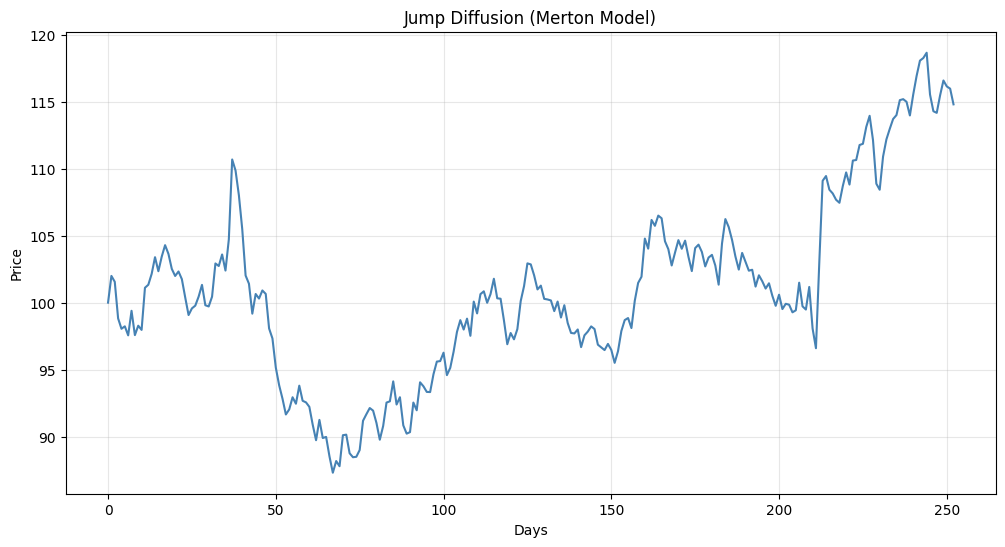

In [35]:
plt.figure(figsize=(12, 6))
plt.plot(prices, color='steelblue', linewidth=1.5)
plt.title("Jump Diffusion (Merton Model)")
plt.xlabel("Days")
plt.ylabel("Price")
plt.grid(True, alpha=0.3)
plt.show()

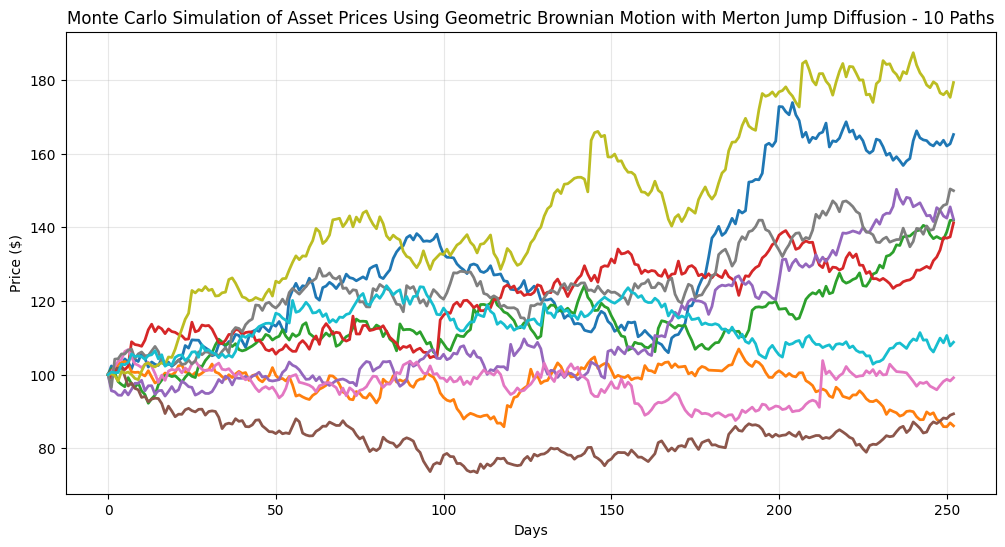

In [36]:
plt.figure(figsize=(12, 6))

for simulation in range(10):
    prices = [S0]

    for step in range(n_steps):
        drift = (mu - sigma**2 / 2) * dt
        random = sigma * np.random.normal(0,1) * np.sqrt(dt)

        n_jumps = np.random.poisson(lam * dt)
        jump = np.sum(np.random.normal(mu_j, sigma_j, n_jumps))

        S_next = prices[-1] * np.exp(drift + random + jump)
        prices.append(S_next)
    plt.plot(prices, linewidth=2, alpha=1)

plt.title("Monte Carlo Simulation of Asset Prices Using Geometric Brownian Motion with Merton Jump Diffusion - 10 Paths")
plt.xlabel("Days")
plt.ylabel("Price ($)")
plt.grid(True, alpha=0.3)
plt.show()        